# Fatores associados à gravidade dos acidentes em rodovias federais brasileiras (2021–2025)

**Disciplina:** Python para Ciência de Dados  
**Atividade:** Atividade Prática Supervisionada (APS)  
**Professor:** Paulo C. Marques F.  
**Integrantes:** Camille Souza, Elora Rocha, Gabriela Afif e Maria Luiza Sevilha

---

## 1. Introdução e relevância

Os acidentes de trânsito são um problema de segurança pública, saúde e infraestrutura. Além das mortes e lesões, geram custos hospitalares, perdas de produtividade, danos materiais e impactos sobre a circulação de pessoas e mercadorias. Nas rodovias federais, o tema ganha peso pela extensão da malha, pelo tráfego entre estados e pela convivência de automóveis, motocicletas, ônibus e caminhões, em vias que sustentam boa parte do transporte de passageiros e de cargas no país.

O problema não está diminuindo. Entre 2021 e 2025, a PRF registrou quase 29 mil mortes nas rodovias federais, e o número de mortes por ano aumentou no período. Isso vai na direção oposta à meta da ONU para a Década de Ação pela Segurança no Trânsito (2021–2030), que propõe reduzir pela metade as mortes e lesões no trânsito.

Nem todo acidente, porém, apresenta as mesmas consequências. Por isso, este trabalho estuda a **gravidade** das ocorrências, e não apenas sua quantidade. Os registros da PRF permitem investigar como a presença de mortos ou feridos graves se associa ao período, ao local, às condições da via e à dinâmica registrada para o acidente.

## 2. Fonte dos dados e delimitação do estudo

O trabalho utiliza os dados abertos de acidentes de trânsito disponibilizados pela Polícia Rodoviária Federal, provenientes do sistema de Boletim de Acidente de Trânsito (BAT). A fonte oficial é o portal [Dados Abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf), acompanhado pelo [dicionário de dados de acidentes](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes).

São analisados os arquivos anuais de **acidentes agrupados por ocorrência** referentes ao período de 1º de janeiro de 2021 a 31 de dezembro de 2025. Cada linha da base representa uma ocorrência registrada pela PRF em uma rodovia federal. Os cinco arquivos possuem a mesma estrutura, com 30 variáveis, e totalizam 342.670 ocorrências identificadas de forma única.

Entre as informações disponíveis estão data, dia da semana e horário, unidade federativa, rodovia, quilômetro e município, causa e tipo do acidente, fase do dia, condições meteorológicas, tipo e traçado da pista, quantidade de veículos e pessoas envolvidas, e números de mortos, feridos e ilesos.

O ano de 2026 não é incluído porque ainda está em andamento, o que produziria uma comparação parcial com os anos completos. As bases agrupadas por pessoa também não são utilizadas neste primeiro escopo, pois possuem outra unidade de análise e poderiam fazer uma mesma ocorrência aparecer em várias linhas.

## 3. Pergunta de pesquisa

A análise é orientada pela seguinte pergunta central:

> **Quais características temporais, espaciais, viárias e ambientais estão associadas à ocorrência de vítimas graves ou mortes nos acidentes registrados pela PRF entre 2021 e 2025?**

Para tornar essa pergunta mensurável, é criada uma variável binária que classificará uma ocorrência como **grave** quando houver pelo menos uma morte ou uma pessoa gravemente ferida:

$$
\text{acidente grave} =
\begin{cases}
1, & \text{se mortos + feridos graves > 0} \\
0, & \text{caso contrário.}
\end{cases}
$$

## 4. Objetivos

### 4.1 Objetivo geral

Descrever os acidentes registrados em rodovias federais brasileiras entre 2021 e 2025 e investigar quais características das ocorrências estão associadas à presença de vítimas graves ou mortes.

### 4.2 Objetivos específicos

1. Descrever a evolução anual das ocorrências e de sua gravidade.
2. Comparar a gravidade segundo tipo de acidente, tipo de pista e trecho urbano ou rural.
3. Ajustar duas regressões logísticas: uma com características de contexto e outra com informações da ocorrência.
4. Avaliar os modelos em 2025, após estimação com os dados de 2021 a 2024.

## 5. Estratégia analítica

A análise combina descrição dos registros, diagnóstico de qualidade e regressões logísticas. O desfecho é a presença de ao menos uma morte ou pessoa gravemente ferida. Os modelos são estimados com 2021–2024 e avaliados em 2025, preservando a ordem temporal. O primeiro usa somente características de contexto; o segundo acrescenta informações registradas sobre a dinâmica da ocorrência. Razões de chances e métricas preditivas são interpretadas como associações, não como efeitos causais.

## 6. Limitações e cuidados de interpretação

Os resultados representarão os acidentes registrados e atendidos pela PRF em rodovias federais, não todos os acidentes de trânsito ocorridos no Brasil. Portanto, as conclusões não devem ser automaticamente generalizadas para vias estaduais ou municipais.

Além disso, a base não fornece medidas de exposição, como fluxo de veículos, quilômetros percorridos ou extensão trafegada em cada local e período. Consequentemente, uma UF ou rodovia com mais ocorrências não pode ser considerada mais perigosa apenas com base na contagem de acidentes: o valor também pode refletir maior volume de tráfego ou maior extensão de rodovia federal.

O estudo tem caráter exploratório e associativo. Relações observadas entre clima, horário, pista, causa ou localização e gravidade não são reportadas como efeitos causais. Também são verificadas possíveis mudanças de categorias, valores ausentes, inconsistências de preenchimento e variáveis com múltiplas classificações antes da construção dos gráficos e do modelo.

No modelo de classificação, variáveis que revelam diretamente o resultado (como número de mortos, número de feridos graves e a classificação final do acidente) não são usadas como preditoras. Essa separação é necessária para evitar vazamento de informação e produzir uma análise interpretável.

---

## 7. Obtenção, organização e qualidade dos dados

Foram utilizados os cinco arquivos anuais de acidentes **agrupados por ocorrência**, disponibilizados pela PRF em formato CSV. Os arquivos brutos foram preservados sem alterações na pasta `dados/brutos`. A importação e a união das bases são realizadas abaixo de forma reproduzível.

### 7.1 Obtenção e arquivos utilizados

Os arquivos `datatran2021.csv` a `datatran2025.csv` foram obtidos no [Portal de Dados Abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf). A opção agrupada por ocorrência foi escolhida porque sua unidade de observação coincide com o objeto do estudo: cada linha representa um acidente. Isso evita que um mesmo acidente seja repetido uma vez para cada pessoa envolvida.

In [1]:
import pandas as pd

dados_2021 = pd.read_csv("dados/brutos/datatran2021.csv", sep=";", encoding="latin1", decimal=",")
dados_2022 = pd.read_csv("dados/brutos/datatran2022.csv", sep=";", encoding="latin1", decimal=",")
dados_2023 = pd.read_csv("dados/brutos/datatran2023.csv", sep=";", encoding="latin1", decimal=",")
dados_2024 = pd.read_csv("dados/brutos/datatran2024.csv", sep=";", encoding="latin1", decimal=",")
dados_2025 = pd.read_csv("dados/brutos/datatran2025.csv", sep=";", encoding="latin1", decimal=",")

### 7.2 Importação e concatenação

Os CSVs usam ponto e vírgula como separador, codificação Latin-1 e vírgula como separador decimal. A variável `ano_arquivo` é acrescentada antes da concatenação para preservar a procedência de cada registro. O identificador é convertido para inteiro anulável e a data para o tipo temporal do Pandas.

In [2]:
dados_2021["ano_arquivo"] = 2021
dados_2022["ano_arquivo"] = 2022
dados_2023["ano_arquivo"] = 2023
dados_2024["ano_arquivo"] = 2024
dados_2025["ano_arquivo"] = 2025

dados = pd.concat(
    [dados_2021, dados_2022, dados_2023, dados_2024, dados_2025],
    ignore_index=True
)

dados["id"] = dados["id"].astype("Int64")
dados["data_inversa"] = pd.to_datetime(dados["data_inversa"], errors="coerce")

print(f"Dimensão da base consolidada: {dados.shape[0]:,} linhas e {dados.shape[1]} colunas")


Dimensão da base consolidada: 342,670 linhas e 31 colunas


In [3]:
resumo_anos = dados.groupby("ano_arquivo", as_index=False).agg(
    ocorrencias=("id", "size"),
    ids_unicos=("id", "nunique"),
    data_inicial=("data_inversa", "min"),
    data_final=("data_inversa", "max")
)


A base consolidada contém **342.670 ocorrências** e 31 colunas: as 30 variáveis originais da PRF mais `ano_arquivo`, criada durante a importação. Todos os anos cobrem o intervalo completo de janeiro a dezembro e apresentam a mesma estrutura de colunas, permitindo a concatenação vertical sem perda de variáveis.

### 7.3 Variáveis disponíveis

As 30 variáveis originais estão organizadas em identificação, tempo, localização, contexto da via e do ambiente, dinâmica do acidente, consequências e unidades administrativas da PRF. As definições completas podem ser consultadas no [dicionário oficial de acidentes agrupados por ocorrência](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes). A divisão em grupos é apenas uma organização analítica deste trabalho.

In [4]:
# As definições completas estão no dicionário oficial indicado acima.

### 7.4 Diagnóstico de qualidade

O diagnóstico abaixo reúne somente as verificações que afetam a confiabilidade da análise: duplicatas, datas, ausências e coerência das variáveis usadas para caracterizar vítimas.

In [5]:
ausentes = dados.isna().sum()
ausentes = ausentes[ausentes > 0]
texto_ausentes = ", ".join(
    [f"{variavel}: {quantidade}" for variavel, quantidade in ausentes.items()]
)

fatal_sem_morto = (
    (dados["classificacao_acidente"] == "Com Vítimas Fatais")
    & (dados["mortos"] == 0)
).sum()

morto_sem_classificacao_fatal = (
    (dados["mortos"] > 0)
    & (dados["classificacao_acidente"] != "Com Vítimas Fatais")
).sum()

feridos_inconsistentes = (
    dados["feridos"]
    != dados["feridos_leves"] + dados["feridos_graves"]
).sum()

base = dados.copy()

base["soma_estados_fisicos"] = (
    base["mortos"]
    + base["feridos_leves"]
    + base["feridos_graves"]
    + base["ilesos"]
    + base["ignorados"]
)
base["diferenca_pessoas"] = (
    base["pessoas"] - base["soma_estados_fisicos"]
)
base["divergencia_pessoas"] = base["diferenca_pessoas"] != 0

divergencias_ano = base.groupby("ano_arquivo", as_index=False).agg(
    ocorrencias=("id", "size"),
    divergencias=("divergencia_pessoas", "sum"),
    percentual=("divergencia_pessoas", "mean")
)

diferencas_frequentes = base.loc[
    base["divergencia_pessoas"], "diferenca_pessoas"
].value_counts()

linhas_qualidade = [
    ["Base", "Ocorrências", f"{len(dados):,.0f}".replace(",", ".")],
    ["Base", "IDs únicos", f"{dados['id'].nunique():,.0f}".replace(",", ".")],
    ["Base", "Linhas duplicadas", dados.duplicated().sum()],
    ["Base", "Datas inválidas", dados["data_inversa"].isna().sum()],
    ["Coerência", "Classificações ausentes", dados["classificacao_acidente"].isna().sum()],
    ["Coerência", "Fatais sem mortos", fatal_sem_morto],
    ["Coerência", "Mortos sem classificação fatal", morto_sem_classificacao_fatal],
    ["Coerência", "Total de feridos inconsistente", feridos_inconsistentes],
    ["Ausências", "Variáveis com valores ausentes", texto_ausentes]
]

for _, linha in divergencias_ano.iterrows():
    resultado = (
        f"{int(linha['divergencias']):,.0f}".replace(",", ".")
        + f" ({linha['percentual']:.2%})".replace(".", ",")
    )
    linhas_qualidade.append([
        "Divergências",
        f"Ocorrências divergentes em {int(linha['ano_arquivo'])}",
        resultado
    ])

linhas_qualidade.append([
    "Divergências",
    "Diferença mais frequente (−1)",
    f"{int(diferencas_frequentes.loc[-1]):,.0f}".replace(",", ".")
])
linhas_qualidade.append([
    "Divergências",
    "Segunda diferença mais frequente (−2)",
    f"{int(diferencas_frequentes.loc[-2]):,.0f}".replace(",", ".")
])

resumo_qualidade = pd.DataFrame(
    linhas_qualidade,
    columns=["grupo", "verificacao", "resultado"]
)

resumo_qualidade

,grupo,verificacao,resultado
0,Base,Ocorrências,342.670
1,Base,IDs únicos,342.670
2,Base,Linhas duplicadas,0
3,Base,Datas inválidas,0
4,Coerência,Classificações ausentes,5
5,Coerência,Fatais sem mortos,0
6,Coerência,Mortos sem classificação fatal,1
7,Coerência,Total de feridos inconsistente,0
8,Ausências,Variáveis com valores ausentes,"classificacao_acidente: 5, regional: 24, deleg..."
9,Divergências,Ocorrências divergentes em 2021,"3.517 (5,45%)"


### 7.5 Divergências no total de pessoas

O dicionário da PRF define `pessoas` como o total de pessoas envolvidas. Entretanto, **18.541 ocorrências (5,41%)** apresentam diferença entre esse total e a soma de mortos, feridos leves, feridos graves, ilesos e pessoas com estado ignorado. Em todos os casos divergentes, a soma dos estados físicos é maior que `pessoas`; as diferenças mais frequentes são −1 e −2. Como o percentual permanece próximo de 5,3% a 5,6% em todos os anos, a inconsistência não parece restrita a um único arquivo.

Não há justificativa documental para corrigir esses registros. Por isso, os valores originais foram preservados e `pessoas` não é usada como preditora nos modelos. O desfecho grave é definido pela presença de mortos ou feridos graves, sem depender do total de pessoas.

### 7.6 Auditoria das categorias usadas nos modelos

As categorias dos principais preditores foram comparadas entre os anos. A auditoria registra a quantidade de categorias, a presença de valores exclusivos de 2025 e possíveis espaços excedentes. Nenhuma categoria é agrupada nesta etapa. Causas raras são agrupadas posteriormente com uma regra definida somente nos dados de treino de 2021–2024.

In [6]:
variaveis_modelo = [
    "uf",
    "condicao_metereologica",
    "tipo_pista",
    "uso_solo",
    "tipo_acidente",
    "causa_acidente"
]

linhas_auditoria = []

for variavel in variaveis_modelo:
    contagens = base.groupby("ano_arquivo")[variavel].nunique()
    categorias_treino = set(base.loc[base["ano_arquivo"] <= 2024, variavel].dropna())
    categorias_teste = set(base.loc[base["ano_arquivo"] == 2025, variavel].dropna())
    valores_texto = base[variavel].dropna().astype(str)
    espacos_excedentes = (valores_texto != valores_texto.str.strip()).sum()

    linhas_auditoria.append({
        "variavel": variavel,
        "2021": contagens[2021],
        "2022": contagens[2022],
        "2023": contagens[2023],
        "2024": contagens[2024],
        "2025": contagens[2025],
        "exclusivas_2025": ", ".join(sorted(categorias_teste - categorias_treino)),
        "espacos_excedentes": espacos_excedentes
    })

auditoria_categorias = pd.DataFrame(linhas_auditoria)

assert (auditoria_categorias["exclusivas_2025"] == "").all()
assert (auditoria_categorias["espacos_excedentes"] == 0).all()

Não foram encontradas categorias exclusivas de 2025 nem valores com espaços excedentes nessas variáveis. A quantidade de categorias de causa e tipo de acidente varia entre anos; por isso, o agrupamento de categorias raras é definido apenas no treino e aplicado, sem alterações, ao teste de 2025.

## 8. Análise exploratória selecionada

A análise exploratória prioriza três resultados diretamente relacionados à pergunta de pesquisa: evolução anual da gravidade, diferenças por tipo de acidente e comparação entre tipo de pista e trecho urbano ou rural. Uma ocorrência é **grave** quando `mortos + feridos_graves > 0`.

### 8.1 Variáveis derivadas

São criados ano, mês, hora, indicador de gravidade e classificação do trecho. Em `uso_solo`, "Sim" representa trecho urbano e "Não" representa trecho rural. A base original `dados` permanece intacta; as transformações ficam em `base`.

In [7]:
from plotnine import *
from mizani.formatters import percent_format

theme_set(theme_bw())

base["ano"] = base["data_inversa"].dt.year
base["mes"] = base["data_inversa"].dt.month
base["hora"] = base["horario"].str[:2].astype(int)
base["grave"] = (
    (base["mortos"] + base["feridos_graves"]) > 0
).astype(int)
base["trecho"] = base["uso_solo"].map({
    "Sim": "Urbano",
    "Não": "Rural"
})

media_grave = base["grave"].mean()

Das 342.670 ocorrências, 96.876 (**28,3%**) são graves. Como a classe de interesse não é rara, não foi necessário usar técnicas de balanceamento no modelo.

### 8.2 Evolução anual

In [8]:
por_ano = base.groupby("ano", as_index=False).agg(
    ocorrencias=("id", "size"),
    graves=("grave", "sum"),
    prop_grave=("grave", "mean"),
    mortos=("mortos", "sum")
)

tabela_anual = por_ano.copy()
tabela_anual["ocorrencias"] = tabela_anual["ocorrencias"].map("{:,.0f}".format).str.replace(",", ".")
tabela_anual["graves"] = tabela_anual["graves"].map("{:,.0f}".format).str.replace(",", ".")
tabela_anual["prop_grave"] = tabela_anual["prop_grave"].map("{:.1%}".format).str.replace(".", ",")
tabela_anual["mortos"] = tabela_anual["mortos"].map("{:,.0f}".format).str.replace(",", ".")

tabela_anual

,ano,ocorrencias,graves,prop_grave,mortos
0,2021,64.567,18.118,"28,1%",5.397
1,2022,64.606,18.409,"28,5%",5.441
2,2023,67.766,19.212,"28,4%",5.627
3,2024,73.202,20.644,"28,2%",6.163
4,2025,72.529,20.493,"28,3%",6.043


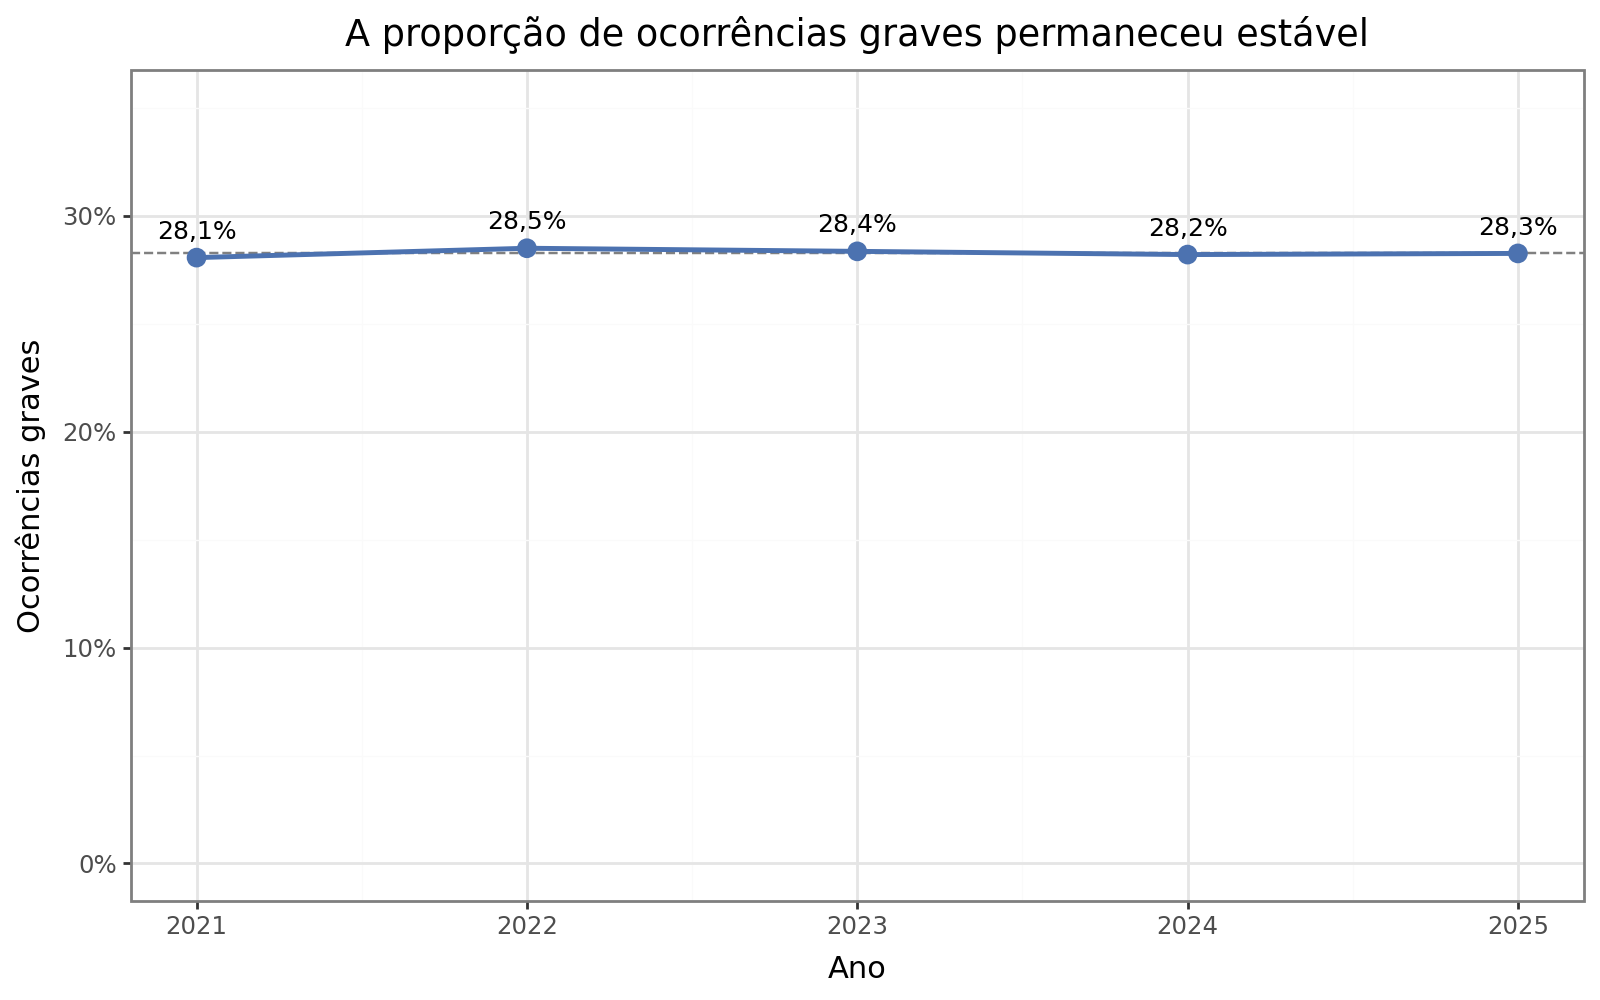

In [9]:
por_ano["rotulo"] = por_ano["prop_grave"].map("{:.1%}".format).str.replace(".", ",")

grafico_anual = (
    ggplot(por_ano, aes(x="ano", y="prop_grave", group=1))
    + geom_hline(yintercept=media_grave, linetype="dashed", color="gray")
    + geom_line(color="#4C72B0", size=1)
    + geom_point(color="#4C72B0", size=3)
    + geom_text(aes(label="rotulo"), nudge_y=0.012, size=9)
    + scale_x_continuous(breaks=range(2021, 2026))
    + scale_y_continuous(labels=percent_format(), limits=(0, 0.35))
    + labs(
        x="Ano",
        y="Ocorrências graves",
        title="A proporção de ocorrências graves permaneceu estável"
    )
    + theme(figure_size=(8, 5))
)

grafico_anual

O número de ocorrências ficou estável em 2021 e 2022 (cerca de 64,6 mil), subiu em 2023 e 2024 (73,2 mil) e permaneceu nesse patamar em 2025, um aumento de 12,3% entre 2021 e 2025. O número de mortos acompanhou esse movimento, de 5.397 para 6.043 (+12,0%). A **proporção observada** de ocorrências graves, porém, permaneceu entre 28,1% e 28,5%. Como a base não traz fluxo de veículos, o aumento das contagens não pode ser interpretado como aumento do risco de trafegar.

### 8.3 Tipo do acidente

Para evitar proporções instáveis, são apresentados apenas tipos com pelo menos 1.000 ocorrências. O tamanho de cada grupo aparece no próprio gráfico. A causa é tratada somente no modelo ampliado, com agrupamento de categorias raras definido no treino.

In [10]:
por_tipo = base.groupby("tipo_acidente", as_index=False).agg(
    ocorrencias=("id", "size"),
    prop_grave=("grave", "mean")
)

por_tipo = por_tipo[por_tipo["ocorrencias"] >= 1000].copy()
por_tipo["n_rotulo"] = por_tipo["ocorrencias"].map("{:,.0f}".format)
por_tipo["n_rotulo"] = por_tipo["n_rotulo"].str.replace(",", ".")
por_tipo["percentual_rotulo"] = por_tipo["prop_grave"].map("{:.1%}".format)
por_tipo["percentual_rotulo"] = por_tipo["percentual_rotulo"].str.replace(".", ",")
por_tipo["rotulo"] = (
    por_tipo["percentual_rotulo"]
    + "\n(n="
    + por_tipo["n_rotulo"]
    + ")"
)

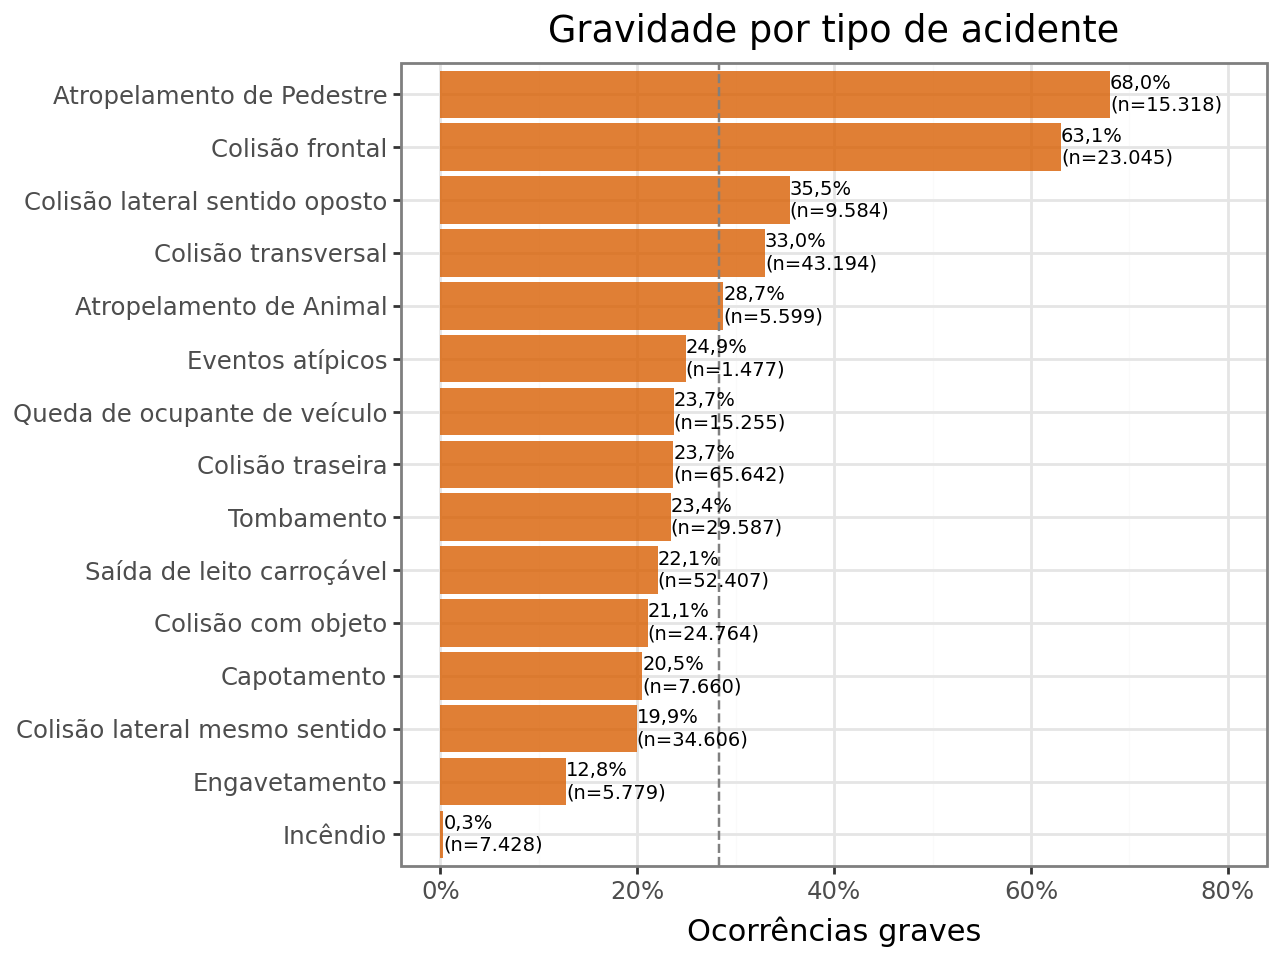

In [11]:
grafico_tipo = (
    ggplot(
        por_tipo,
        aes(
            x="reorder(tipo_acidente, prop_grave)",
            y="prop_grave"
        )
    )
    + geom_col(fill="#D95F02", alpha=0.8)
    + geom_hline(yintercept=media_grave, linetype="dashed", color="gray")
    + geom_text(aes(label="rotulo"), ha="left", size=7)
    + coord_flip()
    + scale_y_continuous(labels=percent_format(), limits=(0, 0.80))
    + labs(
        x="",
        y="Ocorrências graves",
        title="Gravidade por tipo de acidente"
    )
)

grafico_tipo

Atropelamento de pedestre (68,0%; n=15.318) e colisão frontal (63,1%; n=23.045) apresentam as maiores proporções de ocorrências graves e, juntos, representam aproximadamente 11,2% da base. No extremo oposto, engavetamento apresenta 12,8% e incêndio, 0,3%.

O tipo é classificado depois do acidente e, portanto, entra somente no modelo descritivo ampliado, não como informação disponível antes da ocorrência.

### 8.4 Tipo de pista e trecho

A comparação combina tipo de pista e trecho urbano ou rural. Os tamanhos dos seis grupos são mostrados para que diferenças de composição não sejam confundidas com diferenças independentes entre as categorias.

In [12]:
pista_trecho = base.groupby(
    ["tipo_pista", "trecho"],
    as_index=False,
    observed=True
).agg(
    ocorrencias=("id", "size"),
    prop_grave=("grave", "mean")
)

pista_trecho["tipo_pista"] = pd.Categorical(
    pista_trecho["tipo_pista"],
    categories=["Simples", "Dupla", "Múltipla"],
    ordered=True
)
pista_trecho["n_rotulo"] = pista_trecho["ocorrencias"].map("{:,.0f}".format)
pista_trecho["n_rotulo"] = pista_trecho["n_rotulo"].str.replace(",", ".")
pista_trecho["percentual_rotulo"] = pista_trecho["prop_grave"].map("{:.1%}".format)
pista_trecho["percentual_rotulo"] = pista_trecho["percentual_rotulo"].str.replace(".", ",")
pista_trecho["rotulo"] = (
    pista_trecho["percentual_rotulo"]
    + "\n(n="
    + pista_trecho["n_rotulo"]
    + ")"
)
pista_trecho["posicao_rotulo"] = pista_trecho["prop_grave"] + 0.008

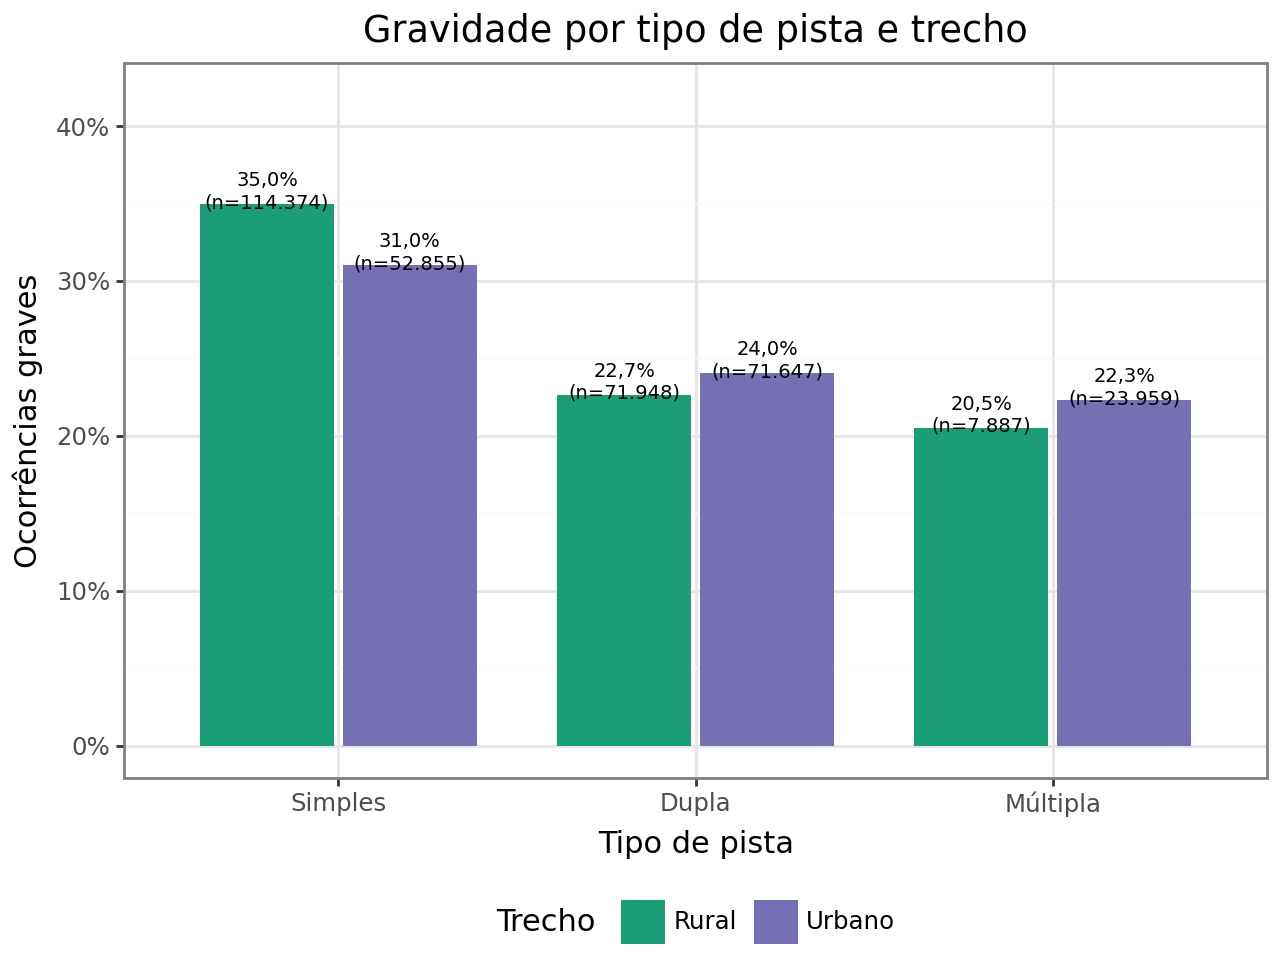

In [13]:
grafico_pista_trecho = (
    ggplot(
        pista_trecho,
        aes(x="tipo_pista", y="prop_grave", fill="trecho")
    )
    + geom_col(position=position_dodge(width=0.8), width=0.75)
    + geom_text(
        aes(y="posicao_rotulo", label="rotulo"),
        position=position_dodge(width=0.8),
        size=7
    )
    + scale_y_continuous(labels=percent_format(), limits=(0, 0.42))
    + scale_fill_manual(values={"Rural": "#1B9E77", "Urbano": "#7570B3"})
    + labs(
        x="Tipo de pista",
        y="Ocorrências graves",
        fill="Trecho",
        title="Gravidade por tipo de pista e trecho"
    )
    + theme(legend_position="bottom")
)

grafico_pista_trecho

Pistas simples apresentam as maiores proporções observadas: 35,0% no trecho rural e 31,0% no urbano. Nas pistas duplas, as proporções são 22,7% no trecho rural e 24,0% no urbano; nas múltiplas, 20,5% e 22,3%, respectivamente.

Essas diferenças representam associações agregadas e podem refletir a composição das ocorrências. A interação entre pista e trecho é examinada no modelo para verificar se a associação entre as duas variáveis muda entre os grupos.

## 9. Modelo de contexto

O primeiro modelo utiliza somente características de contexto: faixa de horário, UF, condição meteorológica, tipo de pista e trecho urbano ou rural. A variável resposta é `grave`, igual a 1 quando há pelo menos uma morte ou pessoa gravemente ferida.

As contagens de vítimas, `classificacao_acidente` e `pessoas` não entram como preditoras, pois revelam ou se relacionam diretamente com a construção do desfecho. Tipo e causa do acidente ficam fora desta especificação e entram no modelo descritivo ampliado da seção 10.

### 9.1 Preparação para a modelagem

As faixas de horário são: madrugada (0h–5h), manhã (6h–11h), tarde (12h–17h) e noite (18h–23h). O treino contém 270.141 ocorrências, com 28,28% graves; o teste contém 72.529, com 28,25% graves. A estimação utiliza 2021–2024 e a avaliação fora da amostra utiliza 2025.

In [14]:
import statsmodels.formula.api as smf
from scipy.stats import chi2
import numpy as np

base["faixa_horaria"] = pd.cut(
    base["hora"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Madrugada", "Manhã", "Tarde", "Noite"]
)

treino = base[base["ano"] <= 2024].copy()
teste = base[base["ano"] == 2025].copy()

variaveis_contexto = [
    "grave",
    "faixa_horaria",
    "uf",
    "condicao_metereologica",
    "tipo_pista",
    "trecho"
]

assert treino[variaveis_contexto].isna().sum().sum() == 0
assert teste[variaveis_contexto].isna().sum().sum() == 0

categorias_novas_2025 = {}

for variavel in variaveis_contexto[1:]:
    categorias_treino = set(treino[variavel].astype(str))
    categorias_teste = set(teste[variavel].astype(str))
    categorias_novas_2025[variavel] = categorias_teste - categorias_treino

assert all(len(categorias) == 0 for categorias in categorias_novas_2025.values())

base["conjunto"] = "treino (2021–2024)"
base.loc[base["ano"] == 2025, "conjunto"] = "teste (2025)"
resumo_conjuntos = base.groupby("conjunto").agg(
    ocorrencias=("id", "size"),
    graves=("grave", "sum"),
    prop_grave=("grave", "mean")
).reset_index()


### 9.2 Modelo A: características de contexto

A regressão logística usa como referências manhã, SP, céu claro, pista dupla e trecho urbano. Assim, cada coeficiente compara uma categoria com sua referência, mantendo constantes as demais variáveis do modelo. A UF é mantida como controle, mas seus 26 coeficientes não são mostrados na tabela compacta.

In [15]:
formula_contexto = """
grave ~ C(faixa_horaria, Treatment(reference='Manhã'))
      + C(uf, Treatment(reference='SP'))
      + C(condicao_metereologica, Treatment(reference='Céu Claro'))
      + C(tipo_pista, Treatment(reference='Dupla'))
      + C(trecho, Treatment(reference='Urbano'))
"""

modelo_contexto = smf.logit(
    formula_contexto,
    data=treino
).fit(disp=False)

assert modelo_contexto.mle_retvals["converged"]

### 9.3 Interação entre tipo de pista e trecho

Uma segunda especificação verifica se a associação entre o tipo de pista e a gravidade muda entre trechos urbanos e rurais. Ela mantém os mesmos controles do Modelo A e acrescenta a interação `tipo_pista × trecho`.

In [16]:
formula_interacao = """
grave ~ C(faixa_horaria, Treatment(reference='Manhã'))
      + C(uf, Treatment(reference='SP'))
      + C(condicao_metereologica, Treatment(reference='Céu Claro'))
      + C(tipo_pista, Treatment(reference='Dupla'))
        * C(trecho, Treatment(reference='Urbano'))
"""

modelo_interacao = smf.logit(
    formula_interacao,
    data=treino
).fit(disp=False)

assert modelo_interacao.mle_retvals["converged"]

estatistica_lr = 2 * (modelo_interacao.llf - modelo_contexto.llf)
graus_liberdade = int(modelo_interacao.df_model - modelo_contexto.df_model)
valor_p_lr = chi2.sf(estatistica_lr, graus_liberdade)

comparacao_modelos = pd.DataFrame({
    "modelo": ["Contexto", "Contexto + interação"],
    "AIC": [modelo_contexto.aic, modelo_interacao.aic],
    "log_verossimilhanca": [modelo_contexto.llf, modelo_interacao.llf],
    "estatistica_LR": [np.nan, estatistica_lr],
    "graus_liberdade": [np.nan, graus_liberdade],
    "valor_p_LR": [np.nan, valor_p_lr]
})

assert valor_p_lr < 0.001

O modelo com interação apresenta AIC menor. O teste de razão de verossimilhanças compara formalmente as duas especificações; um valor-p pequeno indica que a interação acrescenta informação ao modelo de contexto. Por isso, a versão com interação é usada na interpretação e na avaliação de 2025.

### 9.4 *Odds ratios* e interpretação

Os coeficientes da regressão foram transformados em razões de chances (*odds ratios*, OR). Valores acima de 1 indicam chances relativas maiores que a categoria de referência; valores abaixo de 1 indicam chances relativas menores. Essas relações são associações condicionais, não efeitos causais.

In [17]:
intervalos = modelo_interacao.conf_int()

tabela_or = pd.DataFrame({
    "termo": modelo_interacao.params.index,
    "OR": np.exp(modelo_interacao.params.values),
    "IC_95_inferior": np.exp(intervalos[0].values),
    "IC_95_superior": np.exp(intervalos[1].values),
    "valor_p": modelo_interacao.pvalues.values
})

tabela_or = tabela_or[tabela_or["termo"] != "Intercept"]
tabela_or = tabela_or[~tabela_or["termo"].str.contains("C(uf", regex=False)]

nomes_termos = {
    "C(faixa_horaria, Treatment(reference='Manhã'))[T.Madrugada]": "Horário: Madrugada",
    "C(faixa_horaria, Treatment(reference='Manhã'))[T.Tarde]": "Horário: Tarde",
    "C(faixa_horaria, Treatment(reference='Manhã'))[T.Noite]": "Horário: Noite",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Chuva]": "Clima: Chuva",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Garoa/Chuvisco]": "Clima: Garoa/Chuvisco",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Granizo]": "Clima: Granizo",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Ignorado]": "Clima: Ignorado",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Neve]": "Clima: Neve",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Nevoeiro/Neblina]": "Clima: Nevoeiro/Neblina",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Nublado]": "Clima: Nublado",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Sol]": "Clima: Sol",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Vento]": "Clima: Vento",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Múltipla]": "Pista: Múltipla",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Simples]": "Pista: Simples",
    "C(trecho, Treatment(reference='Urbano'))[T.Rural]": "Trecho: Rural",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Múltipla]:C(trecho, Treatment(reference='Urbano'))[T.Rural]": "Interação: Múltipla × Rural",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Simples]:C(trecho, Treatment(reference='Urbano'))[T.Rural]": "Interação: Simples × Rural"
}

tabela_or["termo"] = tabela_or["termo"].replace(nomes_termos)
tabela_or.round({
    "OR": 2,
    "IC_95_inferior": 2,
    "IC_95_superior": 2,
    "valor_p": 3
})

,termo,OR,IC_95_inferior,IC_95_superior,valor_p
1,Horário: Madrugada,1.34,1.30,1.38,0.000
2,Horário: Tarde,1.07,1.05,1.10,0.000
3,Horário: Noite,1.47,1.43,1.50,0.000
30,Clima: Chuva,0.80,0.77,0.82,0.000
31,Clima: Garoa/Chuvisco,0.71,0.68,0.75,0.000
32,Clima: Granizo,0.27,0.03,2.12,0.213
33,Clima: Ignorado,1.10,1.03,1.19,0.007
34,Clima: Neve,0.31,0.04,2.64,0.285
35,Clima: Nevoeiro/Neblina,1.09,0.99,1.19,0.077
36,Clima: Nublado,0.95,0.93,0.98,0.000


Mantidas constantes UF, clima, pista e trecho, ocorrências noturnas apresentam chances relativas de gravidade aproximadamente **47% maiores** que as da manhã; na madrugada, a diferença é de cerca de **34%**, e à tarde, de **7%**.

A interação modifica a leitura das pistas. Em trecho urbano, pista simples apresenta OR de aproximadamente **1,38** em relação à pista dupla. Em trecho rural, essa comparação recebe ainda o multiplicador da interação, próximo de **1,24**; combinados, os termos indicam OR de aproximadamente **1,71** para pista simples contra dupla no meio rural. Esses resultados descrevem associações nos acidentes registrados e não demonstram que o tipo de pista ou o trecho cause a gravidade.

Categorias meteorológicas com poucos registros, como neve e granizo, devem ser interpretadas com cautela, mesmo quando aparecem na tabela.

### 9.5 Objetos preparados para a avaliação

As probabilidades dos dois modelos são calculadas para 2025. Elas são usadas para calcular AUC-ROC, PR-AUC, precisão e revocação junto ao Modelo B.

In [18]:
teste["prob_contexto"] = modelo_contexto.predict(teste)
teste["prob_contexto_interacao"] = modelo_interacao.predict(teste)

assert teste["prob_contexto"].between(0, 1).all()
assert teste["prob_contexto_interacao"].between(0, 1).all()

## 10. Modelo ampliado e avaliação em 2025

### 10.1 Preparação das causas

O Modelo B acrescenta tipo e causa do acidente e número de veículos ao modelo de contexto com interação. Como tipo e causa são registrados depois da ocorrência, esta especificação serve para descrever melhor os acidentes já ocorridos; ela não representa uma previsão que poderia ser feita antes do acidente.

Para evitar coeficientes instáveis, 32 causas com menos de 500 ocorrências no treino, somando 5.293 registros, são reunidas em `Outras`. A regra é definida exclusivamente com 2021–2024 e aplicada sem alteração a 2025.

In [19]:
contagens_causas = treino["causa_acidente"].value_counts()

causas_comuns = set(
    contagens_causas[contagens_causas >= 500].index
)

treino["causa_modelo"] = treino["causa_acidente"].where(
    treino["causa_acidente"].isin(causas_comuns),
    "Outras"
)

teste["causa_modelo"] = teste["causa_acidente"].where(
    teste["causa_acidente"].isin(causas_comuns),
    "Outras"
)

causas_novas = set(teste["causa_modelo"]) - set(treino["causa_modelo"])
tipos_novos = set(teste["tipo_acidente"]) - set(treino["tipo_acidente"])

assert len(causas_novas) == 0
assert len(tipos_novos) == 0


### 10.2 Ajuste do Modelo B

As referências continuam sendo manhã, SP, céu claro, pista dupla e trecho urbano. Para as novas variáveis, as referências são colisão traseira e reação tardia ou ineficiente do condutor, as categorias mais frequentes no treino. `veiculos` permanece numérica e seu OR representa a variação associada a um veículo adicional.

In [20]:
formula_ampliado = """
grave ~ C(faixa_horaria, Treatment(reference='Manhã'))
      + C(uf, Treatment(reference='SP'))
      + C(condicao_metereologica, Treatment(reference='Céu Claro'))
      + C(tipo_pista, Treatment(reference='Dupla'))
        * C(trecho, Treatment(reference='Urbano'))
      + C(tipo_acidente, Treatment(reference='Colisão traseira'))
      + C(causa_modelo, Treatment(reference='Reação tardia ou ineficiente do condutor'))
      + veiculos
"""

modelo_ampliado = smf.logit(
    formula_ampliado,
    data=treino
).fit(disp=False, maxiter=100)

assert modelo_ampliado.mle_retvals["converged"]

teste["prob_ampliado"] = modelo_ampliado.predict(teste)

assert teste["prob_ampliado"].between(0, 1).all()


### 10.3 *Odds ratios* do Modelo B

A tabela apresenta o número de veículos, os tipos com pelo menos 1.000 ocorrências no treino e as dez causas não usadas como referência mais frequentes. Todos os demais coeficientes continuam estimados, mas são omitidos para manter a saída legível. O AIC diminui de 312.209,03 no modelo de contexto com interação para 285.925,82 no modelo ampliado.

In [21]:
intervalos_ampliado = modelo_ampliado.conf_int()

tabela_or_ampliado_completa = pd.DataFrame({
    "termo": modelo_ampliado.params.index,
    "OR": np.exp(modelo_ampliado.params.values),
    "IC_95_inferior": np.exp(intervalos_ampliado[0].values),
    "IC_95_superior": np.exp(intervalos_ampliado[1].values),
    "valor_p": modelo_ampliado.pvalues.values
})

tipos_frequentes = treino["tipo_acidente"].value_counts()
tipos_frequentes = tipos_frequentes[tipos_frequentes >= 1000].index

causas_frequentes = contagens_causas.drop(
    "Reação tardia ou ineficiente do condutor"
).head(10).index

termos_exibidos = ["veiculos"]
rotulos_ampliado = {"veiculos": "Número de veículos"}

for tipo in tipos_frequentes:
    if tipo != "Colisão traseira":
        termo = "C(tipo_acidente, Treatment(reference='Colisão traseira'))[T." + tipo + "]"
        termos_exibidos.append(termo)
        rotulos_ampliado[termo] = "Tipo: " + tipo

for causa in causas_frequentes:
    termo = "C(causa_modelo, Treatment(reference='Reação tardia ou ineficiente do condutor'))[T." + causa + "]"
    termos_exibidos.append(termo)
    rotulos_ampliado[termo] = "Causa: " + causa

tabela_or_ampliado = tabela_or_ampliado_completa[
    tabela_or_ampliado_completa["termo"].isin(termos_exibidos)
].copy()

tabela_or_ampliado["termo"] = tabela_or_ampliado["termo"].replace(
    rotulos_ampliado
)

tabela_or_ampliado.round({
    "OR": 2,
    "IC_95_inferior": 2,
    "IC_95_superior": 2,
    "valor_p": 3
})

,termo,OR,IC_95_inferior,IC_95_superior,valor_p
42,Tipo: Atropelamento de Animal,1.35,1.17,1.55,0.000
43,Tipo: Atropelamento de Pedestre,5.03,4.72,5.36,0.000
44,Tipo: Capotamento,0.91,0.85,0.97,0.006
45,Tipo: Colisão com objeto,0.99,0.94,1.03,0.544
46,Tipo: Colisão frontal,3.73,3.57,3.90,0.000
48,Tipo: Colisão lateral mesmo sentido,0.79,0.76,0.82,0.000
49,Tipo: Colisão lateral sentido oposto,1.08,1.02,1.14,0.009
50,Tipo: Colisão transversal,1.48,1.42,1.55,0.000
52,Tipo: Engavetamento,0.40,0.36,0.43,0.000
53,Tipo: Eventos atípicos,1.13,0.99,1.30,0.079


### 10.4 Avaliação temporal

Os três modelos são avaliados nas mesmas 72.529 ocorrências de 2025. AUC-ROC e PR-AUC avaliam as probabilidades em vários limiares. Precisão e revocação usam o limiar fixo de 0,5, definido sem consultar os resultados do teste.

In [22]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve
)

modelos_avaliados = {
    "Contexto": teste["prob_contexto"],
    "Contexto + interação": teste["prob_contexto_interacao"],
    "Ampliado": teste["prob_ampliado"]
}

linhas_metricas = []
linhas_roc = []
linhas_pr = []

for nome, probabilidades in modelos_avaliados.items():
    previsoes = (probabilidades >= 0.5).astype(int)
    vn, fp, fn, vp = confusion_matrix(teste["grave"], previsoes).ravel()

    linhas_metricas.append({
        "modelo": nome,
        "AUC_ROC": roc_auc_score(teste["grave"], probabilidades),
        "PR_AUC": average_precision_score(teste["grave"], probabilidades),
        "precisao": precision_score(teste["grave"], previsoes, zero_division=0),
        "revocacao": recall_score(teste["grave"], previsoes),
        "previstos_graves": previsoes.sum(),
        "VP": vp,
        "FP": fp,
        "VN": vn,
        "FN": fn
    })

    fpr, tpr, limites_roc = roc_curve(teste["grave"], probabilidades)
    precisao_curva, revocacao_curva, limites_pr = precision_recall_curve(
        teste["grave"], probabilidades
    )

    linhas_roc.append(pd.DataFrame({
        "fpr": fpr,
        "tpr": tpr,
        "modelo": nome
    }))

    linhas_pr.append(pd.DataFrame({
        "revocacao": revocacao_curva,
        "precisao": precisao_curva,
        "modelo": nome
    }))

tabela_metricas = pd.DataFrame(linhas_metricas)
curvas_roc = pd.concat(linhas_roc, ignore_index=True)
curvas_pr = pd.concat(linhas_pr, ignore_index=True)

tabela_metricas.round(3)

,modelo,AUC_ROC,PR_AUC,precisao,revocacao,previstos_graves,VP,FP,VN,FN
0,Contexto,0.609,0.376,0.543,0.019,731,397,334,51702,20096
1,Contexto + interação,0.610,0.377,0.530,0.023,878,465,413,51623,20028
2,Ampliado,0.704,0.515,0.653,0.253,7923,5175,2748,49288,15318


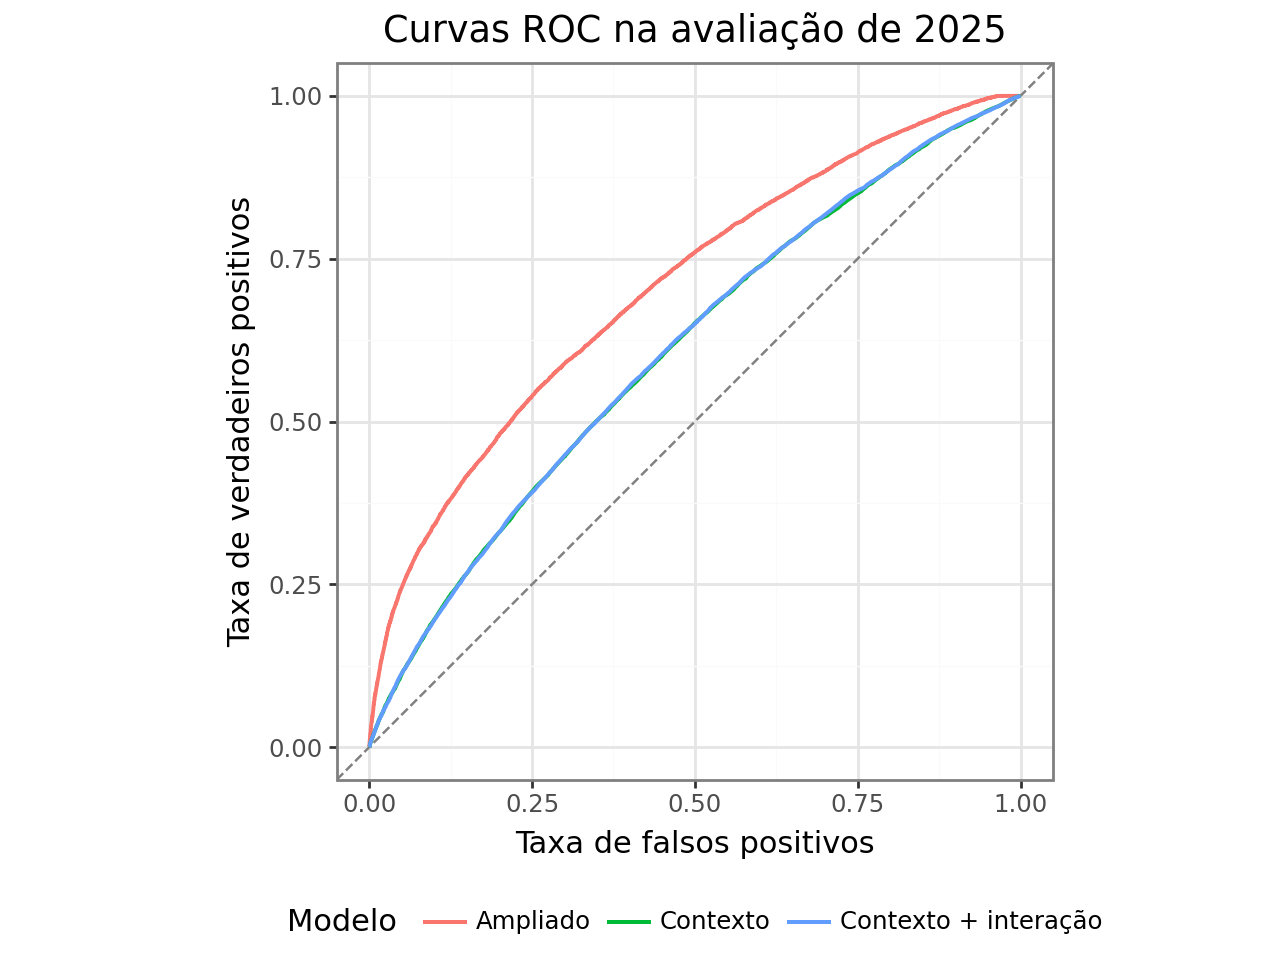

In [23]:
grafico_roc = (
    ggplot(curvas_roc, aes(x="fpr", y="tpr", color="modelo"))
    + geom_abline(linetype="dashed", color="gray")
    + geom_line(size=0.8)
    + coord_equal()
    + labs(
        x="Taxa de falsos positivos",
        y="Taxa de verdadeiros positivos",
        color="Modelo",
        title="Curvas ROC na avaliação de 2025"
    )
    + theme(legend_position="bottom")
)

grafico_roc

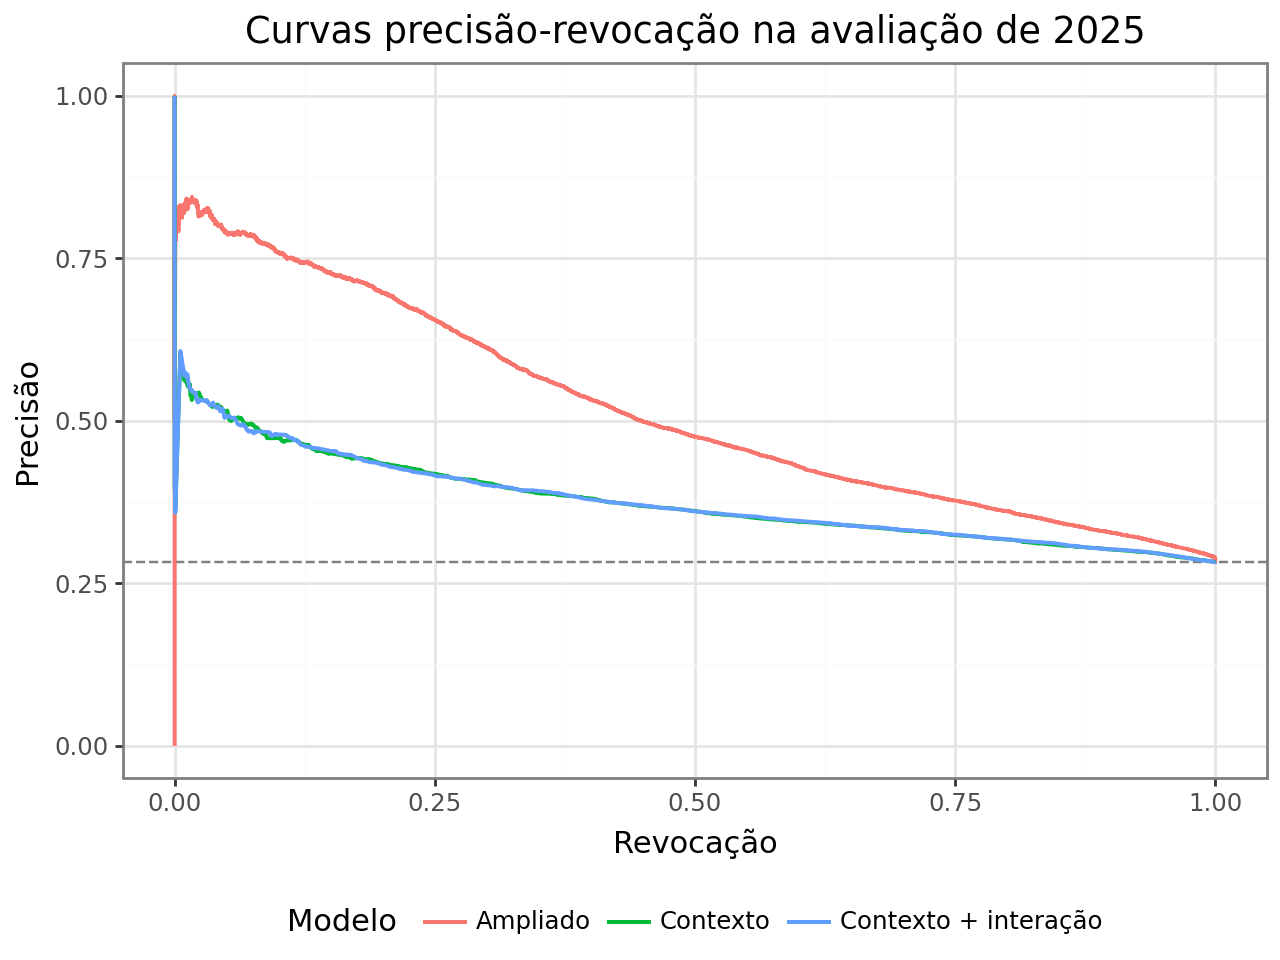

In [24]:
prevalencia_2025 = teste["grave"].mean()

grafico_pr = (
    ggplot(curvas_pr, aes(x="revocacao", y="precisao", color="modelo"))
    + geom_hline(
        yintercept=prevalencia_2025,
        linetype="dashed",
        color="gray"
    )
    + geom_line(size=0.8)
    + coord_cartesian(xlim=(0, 1), ylim=(0, 1))
    + labs(
        x="Revocação",
        y="Precisão",
        color="Modelo",
        title="Curvas precisão-revocação na avaliação de 2025"
    )
    + theme(legend_position="bottom")
)

grafico_pr

### 10.5 Interpretação da avaliação

Os modelos de contexto apresentam desempenhos semelhantes: a AUC-ROC passa de 0,609 para 0,610 com a interação, e a PR-AUC fica próxima de 0,377. Portanto, embora a interação melhore o ajuste no treino, seu ganho de discriminação em 2025 é pequeno.

O Modelo B apresenta maior capacidade de separar ocorrências graves e não graves, com AUC-ROC de **0,704** e PR-AUC de **0,515**. Essa melhora deve ser interpretada com cautela, pois parte dela vem de informações sobre a dinâmica do acidente registradas depois que ele aconteceu.

No limiar de 0,5, o Modelo B alcança precisão de **65,3%** e revocação de **25,3%**. Assim, cerca de dois terços das ocorrências classificadas como graves realmente são graves, mas o modelo identifica somente um quarto de todos os casos graves. Os modelos de contexto apresentam revocação ainda menor, próxima de 2%. As curvas mostram esse compromisso sem depender de um único limiar.

## 11. Conclusão

Entre 2021 e 2025, a quantidade anual de acidentes registrados pela PRF aumentou, mas a proporção de ocorrências graves permaneceu próxima de 28,3%. Atropelamentos de pedestres e colisões frontais apresentaram as maiores proporções observadas de gravidade, enquanto tipo de pista e trecho mostraram associações que precisam ser analisadas conjuntamente.

No modelo de contexto, horário, UF, clima, pista e trecho estiveram associados à gravidade. A interação indicou que a comparação entre tipos de pista muda entre trechos urbanos e rurais, embora tenha produzido ganho pequeno na avaliação de 2025. Os dois modelos de contexto apresentaram AUC-ROC próxima de 0,61 e PR-AUC próxima de 0,38.

Ao acrescentar tipo, causa e número de veículos, o Modelo B alcançou AUC-ROC de 0,704 e PR-AUC de 0,515. No limiar de 0,5, sua precisão foi de 65,3% e sua revocação de 25,3%, mostrando que ele ainda deixa de identificar aproximadamente três quartos das ocorrências graves. Como tipo e causa são registrados depois da ocorrência, esse ganho representa capacidade descritiva ampliada e não uma previsão operacional anterior ao acidente.

Os resultados não permitem afirmar relações causais nem identificar UFs ou rodovias como mais perigosas, pois a base não contém medidas de exposição ao tráfego. Eles se aplicam aos acidentes registrados pela PRF em rodovias federais e também estão sujeitos a erros de classificação, categorias raras e valores extremos, como o registro de 131 veículos.

Apesar dessas limitações, a análise identifica características associadas à presença de mortos ou feridos graves e mostra a importância de separar informações de contexto daquelas conhecidas somente depois do acidente.

## Referências

IPEA; POLÍCIA RODOVIÁRIA FEDERAL. **Acidentes de trânsito nas rodovias federais brasileiras: caracterização, tendências e custos para a sociedade**. Brasília: Ipea, 2015. (Relatório de Pesquisa).

ORGANIZAÇÃO DAS NAÇÕES UNIDAS. **Resolução A/RES/74/299: Melhorando a segurança no trânsito global**. Nova York: Assembleia Geral, 2020.

POLÍCIA RODOVIÁRIA FEDERAL. **Dados Abertos da PRF**. Disponível em: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf>. Acesso em: 19 out. 2026.

POLÍCIA RODOVIÁRIA FEDERAL. **Dicionário de dados - Acidentes**. Disponível em: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes>. Acesso em: 19 out. 2026.